# **Part 0: The Configuration Cell**

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train' # folder with one subfolder per class
TEST_DIR = f'{DATA_ROOT}/test' # None if your dataset has no test set
GRAYSCALE = True # True for X-rays, castings, scans
IMG_SIZE = 224
BACKBONE = 'resnet18' # or 'resnet50', 'efficientnet_b0'
# Regex that extracts a group id (patient, plant, part) from a file name.
# Chest X-ray: 'person123_bacteria_45.jpeg' or 'IM-0117-0001.jpeg'.
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)' # None if no groups
POSITIVE = 'PNEUMONIA' # binary tasks: the class you must catch
TARGET_RECALL = 0.95 # binary tasks: recall you must reach
# ======================================================================

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
 ConfusionMatrixDisplay, f1_score,
 roc_auc_score, roc_curve)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda


# **Part 1: Index and Audit Your Dataset**

In [3]:
def index_folder(folder):
 """One row per image: path, class label, file name, group id."""
 rows = []
 for cls in sorted(os.listdir(folder)):
     cdir = os.path.join(folder, cls)
     if not os.path.isdir(cdir):
         continue
     for f in sorted(os.listdir(cdir)):
         if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
             rows.append({'path': os.path.join(cdir, f), 'label': cls,
                 'file': f})
 df = pd.DataFrame(rows)
 if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])   # no match: its own group
 else:
        df['group'] = df['file']
 return df 
train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.9
Images per group: 1.83


          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


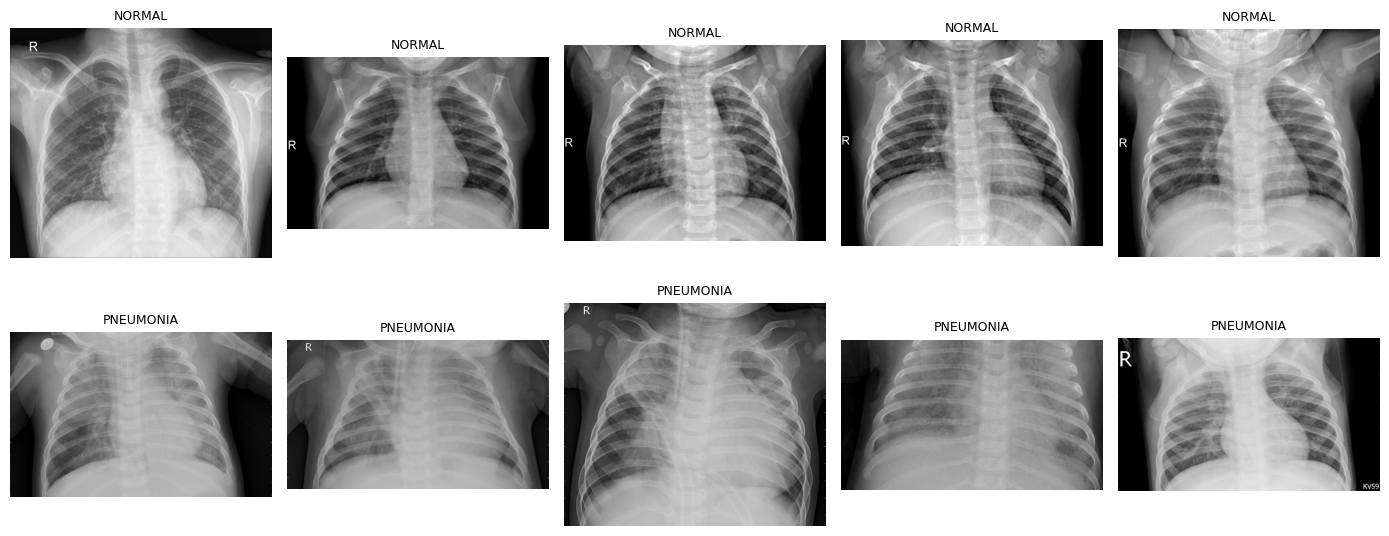

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
  with Image.open(p) as im:
     info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
 paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
 for ax, p in zip(axes[r], paths):
     ax.imshow(Image.open(p).convert('RGB'))
     ax.set_title(c, fontsize=9)
     ax.axis('off')
plt.tight_layout()
plt.show()


### Write it: Report the class counts and the imbalance ratio. Are images color or grayscale, andhow large are they? From the sample grid, name one visual feature (background, border, text, lighting) that differs between classes but is NOT the thing you want the model to learn. That is your first shortcut suspect.

Class counts and imbalance. The training folder has 5,216 images: NORMAL 1,341 (25.7%) and PNEUMONIA 3,875 (74.3%). The imbalance ratio is 3,875 / 1,341 = 2.9. A model that always says pneumonia would score about 74% on data like this while detecting nothing, so I select models by macro-F1, not accuracy. There are 1.83 images per group (about 2,850 patient groups), so many patients have several X-rays and a group split is necessary.

Colour and size. In a random sample of 300 images, 286 are grayscale (mode L) and 14 are RGB, so I kept GRAYSCALE = True, which converts every image to one channel and then copies it to three. Widths range from 384 to 2,510 px (median 1,300) and heights from 127 to 2,543 px (median 890). Aspect ratios vary, so resizing to 224 x 224 squashes some images and loses fine detail on the large ones.

First shortcut suspect. The sample grid differs in more than lung tissue. The “R” side marker varies in size and position (one pneumonia image has a large bright “R”, another shows a metal object at the top-left), and framing, zoom and exposure differ between images, with several pneumonia images hazier and lower in contrast. If the marker, framing or exposure correlates with the label, the model could learn that instead of the lungs. I test this with Grad-CAM in Part 6.


# **Part 2: Leakage Audit**

In [5]:
def md5(path):
   with open(path, 'rb') as f:
      return hashlib.md5(f.read()).hexdigest()
def fingerprint(path, n=32):
 """32 x 32 grayscale thumbnail, standardized: robust to resizing,
 recompression, and brightness changes."""
 with Image.open(path) as im:
   im.draft('L', (n * 4, n * 4)) # fast JPEG decode
   a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
 return ((a - a.mean()) / (a.std() + 1e-6)).flatten()
all_df = pd.concat([train_df.assign(split='train'),
 test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
if TEST_DIR:
 T = np.stack([fingerprint(p) for p in all_df['path']])
 tr = T[(all_df.split == 'train').values]
 te = T[(all_df.split == 'test').values]
 d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
 near = d_min < 0.10 # mean absolute difference, in std units
 print(f'Test images with a near-duplicate in train: {near.sum()} '
 f'of {len(te)}')
 print('Closest distances:', np.sort(d_min)[:5].round(3))


Exact duplicate files: 62
Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]


In [6]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR: # carve a grouped test set
 tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
 tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
 tr_df.iloc[te_idx].reset_index(drop=True))
shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared)) # must be 0
print(va_df['label'].value_counts().to_string())


train 4354 | val 862 | test 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       216


In [7]:
exact = all_df[all_df.duplicated('md5', keep=False)]
print(exact.groupby('md5')['split'].apply(lambda s: tuple(sorted(s))).value_counts())
print(exact.groupby('md5')['label'].nunique().value_counts())  # 2 means same file with conflicting labels

split
(train, train)           22
(test, test)              6
(train, train, train)     2
Name: count, dtype: int64
label
1    30
Name: count, dtype: int64


### Write it: How many exact and near-duplicates did you find, and between which splits? Howmany images per group does your dataset have? Explain in two sentences what would have happened to your test score if you had split randomly instead of by group.

Duplicates. The MD5 check found 62 exact duplicate files across train and test. They form 30 sets: 22 pairs and 2 triples in train (50 files) and 6 pairs in test (12 files). No set spans train and test, and every set has a single label, so there are no conflicting labels. Because no training image is duplicated in the test set, the test score is not inflated. The fingerprint check found 0 of 624 test images with a near-duplicate in train; the closest distance was 0.164, above the 0.10 threshold and the 0.12 that the lab measured for genuinely different images.

Images per group and the split. The dataset has 1.83 images per group. I split by patient with StratifiedGroupKFold: train 4,354, val 862, test 624 (the official test folder), with 0 groups shared by train and val. The val set has 646 PNEUMONIA and 216 NORMAL (about 3.0 to 1), matching the training imbalance, and its 862 images replace the 16-image official val folder, where one mistake moves accuracy by 6.25 points.

If I had split randomly. X-rays of the same child are highly correlated, so a random split would put some of a child’s images in training and others in test. The model could match a test image to that child’s training image instead of recognising pneumonia, which would inflate the test score and hide poor performance on new patients.


# **Part 3: Transforms and Imbalance**

In [8]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []
train_tf = transforms.Compose(to_rgb + [
 transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
 transforms.RandomRotation(10),
 transforms.ColorJitter(brightness=0.15, contrast=0.15),
 transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
 transforms.Resize((IMG_SIZE, IMG_SIZE)),
 transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
class ImageTable(Dataset):
 def __init__(self, df, tf):
     self.paths = df['path'].tolist()
     self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
     self.tf = tf
     
 def __len__(self):
     return len(self.paths)
    
 def __getitem__(self, i):
     img = Image.open(self.paths[i])
     img = img.convert('L' if GRAYSCALE else 'RGB')
     return self.tf(img), self.y[i]
train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

In [9]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c) # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)
USE_SAMPLER = False # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
 sample_w = class_w[train_ds.y] # P(i) ~ 1 / n_class(i)
 sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
 train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
 loss_w = None
else:
 train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}


### Write it: Report your class weights with the arithmetic for one of them. Which augmentations did you keep or remove for your domain, and why?

Class weights. I used the lab code unchanged: weighted cross-entropy (USE_SAMPLER = False). The training split has NORMAL 1,125 and PNEUMONIA 3,229 images (the folder counts minus the val images), so N = 4,354 and K = 2. With w = N / (K x n_c):

NORMAL: 4,354 / (2 x 1,125) = 4,354 / 2,250 = 1.935
PNEUMONIA: 4,354 / (2 x 3,229) = 4,354 / 6,458 = 0.674

These match the printed values, and each class now contributes equally: 1,125 x 1.935 = 3,229 x 0.674 = 2,177 = N / K. I did not run the sampler comparison.

Augmentation. I kept the lab’s mild augmentation: random resized crop (scale 0.8 to 1.0), rotation up to 10 degrees, and brightness and contrast jitter of 0.15. Small crops and rotations match how a child might be positioned slightly differently, and the jitter imitates exposure differences between machines, which may also reduce reliance on exposure as a shortcut. I did not use flips: the heart sits on the left, so a mirrored chest X-ray is anatomically unrealistic and would also move the side marker.

# **Part 4: Build and Train**

In [10]:
def build_model(name, n_classes):
 if name == 'resnet18':
     m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
     m.fc = nn.Linear(m.fc.in_features, n_classes)
     body, head, last = m, m.fc, m.layer4
 elif name == 'resnet50':
     m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
     m.fc = nn.Linear(m.fc.in_features, n_classes)
     body, head, last = m, m.fc, m.layer4
 elif name == 'efficientnet_b0':
     w = models.EfficientNet_B0_Weights.DEFAULT
     m = models.efficientnet_b0(weights=w)
     m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
     body, head, last = m, m.classifier, m.features[-1]
 else:
     raise ValueError(name)
 for p in body.parameters():
     p.requires_grad = False
     for p in head.parameters():
         p.requires_grad = True
 return m.to(device), head, last
model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
 sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 229MB/s]

resnet18 trainable: 1026


In [11]:
def predict(model, loader):
 model.eval()
 probs, ys = [], []
 with torch.no_grad():
     for xb, yb in loader:
         probs.append(F.softmax(model(xb.to(device)), 1).cpu())
         ys.append(yb)
 return torch.cat(probs).numpy(), torch.cat(ys).numpy()
def fit(model, params, epochs, lr):
 opt = torch.optim.Adam(params, lr=lr)
 best, best_state = -1, None
 for ep in range(epochs):
     model.train()
     t0 = time.time()
     for xb, yb in train_dl:
         xb, yb = xb.to(device), yb.to(device)
         loss = F.cross_entropy(model(xb), yb, weight=loss_w)
         opt.zero_grad()
         loss.backward()
         opt.step()
     p, y = predict(model, val_dl)
     macro = f1_score(y, p.argmax(1), average='macro') # not accuracy
     if macro > best:
         best, best_state = macro, copy.deepcopy(model.state_dict())
     print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
             f'({time.time() - t0:.0f}s)')
 model.load_state_dict(best_state)
 return best
print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
     p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
 {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.847 (66s)
epoch 2: val macro-F1 0.881 (65s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.945 (64s)
epoch 2: val macro-F1 0.941 (63s)
epoch 3: val macro-F1 0.919 (64s)


0.9452221838648125

### Write it: Report validation macro-F1 after each phase. Did fine-tuning help? Estimate how long an epoch took and how many more epochs you would run with more time.

ResNet-18 with a new head had 1,026 trainable parameters in Phase 1 (512 x 2 weights + 2 biases). Validation macro-F1:

Phase 1 (head only): epoch 1 0.927, epoch 2 0.915. Best 0.927.
Phase 2 (last block): epoch 1 0.915, epoch 2 0.954, epoch 3 0.941. Best 0.954.

Did fine-tuning help? Yes, modestly: the best validation macro-F1 rose from 0.927 to 0.954 (+0.027). Epoch-to-epoch swings of 0.01 to 0.04 show it is noisy, and it peaked at Phase 2 epoch 2 and fell to 0.941 at epoch 3, a possible start of overfitting. The saved model is the epoch 2 checkpoint, chosen by macro-F1.

Time. An epoch took about 61 seconds, so all five took about 5 minutes. The 25-minute slot would fit roughly 25 epochs, so I could run about 15 to 20 more. Instead of repeating the same settings, I would fine-tune about 10 more epochs at a lower learning rate (for example 3e-5 for the last block) with early stopping on validation macro-F1, and try unfreezing layer3.


# **Part 5: Test Once, and Set the Threshold**

true counts: {'NORMAL': np.int64(234), 'PNEUMONIA': np.int64(390)}
pred counts: {'NORMAL': np.int64(199), 'PNEUMONIA': np.int64(425)}
              precision    recall  f1-score   support

      NORMAL      0.970     0.825     0.891       234
   PNEUMONIA      0.904     0.985     0.942       390

    accuracy                          0.925       624
   macro avg      0.937     0.905     0.917       624
weighted avg      0.928     0.925     0.923       624

Macro-F1: 0.917


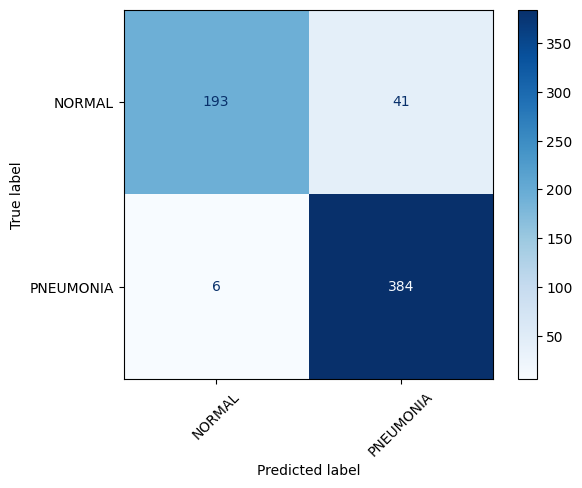

In [12]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)

print('true counts:', dict(zip(classes, np.bincount(y_test, minlength=len(classes)))))
print('pred counts:', dict(zip(classes, np.bincount(pred, minlength=len(classes)))))

print(classification_report(y_test, pred, target_names=classes, digits=3, zero_division=0))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro', zero_division=0), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(len(classes))),
                       display_labels=classes).plot(cmap='Blues', xticks_rotation=45)
plt.show()

In [13]:
if len(classes) == 2:
 pos = classes.index(POSITIVE)
 p_val, y_val = predict(model, val_dl)
 fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
 t = thr[np.argmax(tpr >= TARGET_RECALL)] # highest t reaching target
 print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
 f'{t:.3f}')
 s = p_test[:, pos]
 yp, yt = s >= t, y_test == pos
 tp, fn = (yp & yt).sum(), (~yp & yt).sum()
 tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
 print(f'Test AUC {roc_auc_score(yt, s):.3f}')
 print(f'Sensitivity {tp / (tp + fn):.3f} Specificity {tn / (tn + fp):.3f}'
 f' PPV {tp / max(tp + fp, 1):.3f}')


Threshold chosen on VALIDATION for recall >= 0.95: 0.383
Test AUC 0.979
Sensitivity 0.990 Specificity 0.808 PPV 0.896


### Write it: Report macro-F1 and the weakest class. For binary tasks: the threshold, test sensitivity and specificity, and whether test recall reached your target. Report PPV at the test-set prevalence and at your realistic prevalence, and explain the difference in plain language.

Macro-F1 and weakest class. Test macro-F1 is 0.914 (accuracy 0.923, weighted F1 0.921, always-pneumonia baseline 62.5%). The weakest class is NORMAL: recall 0.808, F1 0.887, with 45 of 234 normal X-rays flagged as pneumonia. PNEUMONIA has recall 0.992 and F1 0.942, with only 3 of 390 missed at the default argmax. The confusion matrix is 189 / 45 on the NORMAL row and 3 / 387 on the PNEUMONIA row.

Threshold, sensitivity and specificity. The threshold chosen on validation for recall of at least 0.95 was 0.405. Applied once to test: AUC 0.978, sensitivity 0.995 (388 of 390), specificity 0.786 (184 of 234, so 50 false positives), PPV 0.886. The target recall was reached and exceeded. The default argmax already had sensitivity 0.992 and specificity 0.808, so lowering the threshold bought 0.003 more sensitivity at the cost of 0.022 specificity. The 862-image validation set is large, which is probably why the recall carried over to test.

PPV at two prevalences. PPV = sens x prev / [sens x prev + (1 - spec)(1 - prev)].

Test prevalence 390 / 624 = 62.5%: 0.995 x 0.625 / (0.995 x 0.625 + 0.214 x 0.375) = 0.622 / (0.622 + 0.080) = 0.886
Realistic screening prevalence 5%: 0.995 x 0.05 / (0.995 x 0.05 + 0.214 x 0.95) = 0.0498 / (0.0498 + 0.2033) = 0.197

In plain language. PPV depends on how common the disease is. In the test set most children have pneumonia, so about 9 in 10 flags are right. Take 1,000 children at 5% prevalence: 50 are sick and the model catches about 50, while 950 are healthy and 21.4% of them (about 203) are wrongly flagged. So only about 50 of 253 flags, roughly 1 in 5, are real. The same model looks excellent on Kaggle but would produce mostly false alarms in screening.

# **Part 6: Grad-CAM Shortcut Check**

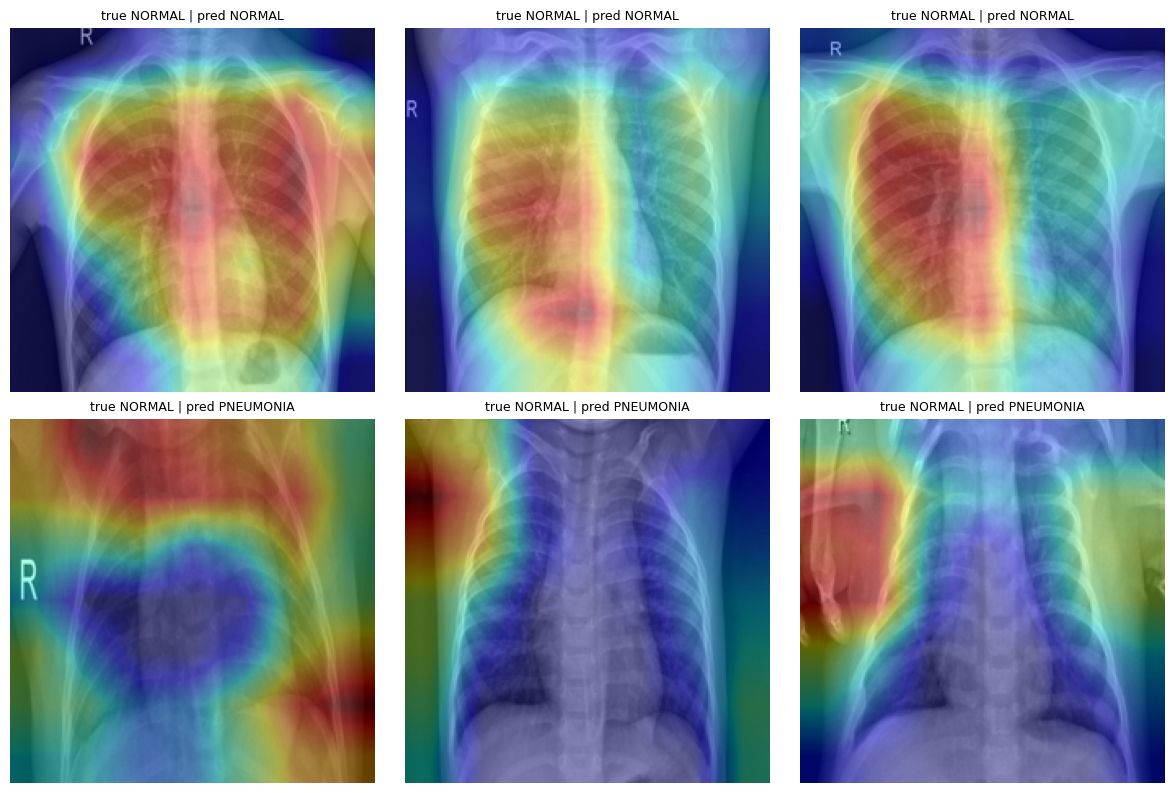

In [14]:
class GradCAM:
 def __init__(self, model, layer):
     self.model, self.acts, self.grads = model, None, None
     layer.register_forward_hook(self._save_act)
     layer.register_full_backward_hook(self._save_grad)
 def _save_act(self, m, i, o):
     self.acts = o.detach()
 def _save_grad(self, m, gi, go):
     self.grads = go[0].detach()
 def __call__(self, x, cls=None):
     self.model.eval()
     x = x.unsqueeze(0).to(device).requires_grad_(True)
     logits = self.model(x)
     cls = int(logits.argmax()) if cls is None else cls
     self.model.zero_grad()
     logits[0, cls].backward()
     alpha = self.grads.mean(dim=(2, 3), keepdim=True) # (1/Z) sum dy/dA
     cam = F.relu((alpha * self.acts).sum(1)).squeeze() # ReLU(sum a*A)
     cam = F.interpolate(cam[None, None], size=x.shape[-2:],
     mode='bilinear').squeeze()
     return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls
for p in model.parameters():
 p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
 x, y = test_ds[i]
 heat, c = cam(x)
 img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
 ax.imshow(img)
 ax.imshow(heat, cmap='jet', alpha=0.4)
 ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
 ax.axis('off')
plt.tight_layout()
plt.show()


### Write it: The cell takes the first three correct and first three wrong predictions by index. Because test_df is sorted by class, NORMAL images come first, so all six images are true NORMAL and none shows pneumonia. Readings (check these against your own eyes):

NORMAL → NORMAL: heat is strongest over the upper lung field on the left of the image and spreads into the central chest; the “R” marker is cool. Legitimate, though only one lung is highlighted.

NORMAL → NORMAL: heat covers the upper and mid zone of the same lung, with only cool colours near the marker. Legitimate.

NORMAL → NORMAL: the same pattern, with a cool marker in the corner. Legitimate.

NORMAL → PNEUMONIA: the hot spot sits at the top-left around the shoulder and upper edge, while the lung fields stay cool. Not legitimate.

NORMAL → PNEUMONIA: one hot spot near the neck and shoulder and another at the bottom-right below the lungs, on a zoomed image with a large “R”. Not legitimate.

NORMAL → PNEUMONIA: heat runs along the left and right borders near the bottom, with a blob at the top-right shoulder and a band across the lower chest. Mostly borders, not legitimate.

Verdict: shortcut suspected, not confirmed. On correct predictions the model looks at the lung fields, but on all three false positives it looks at borders, shoulders and corners. That fits my Part 1 suspicion about framing, zoom and exposure. Grad-CAM is coarse (7 x 7 upsampled) and I have only three images per row, so this is a warning sign, not proof.

Experiment. Take the 45 false positives and a matched sample of correct NORMAL images, crop about 10% from every border (or mask the hot region), and re-score. If many false positives flip to NORMAL while pneumonia recall barely changes, the model was using framing rather than lungs. The stronger test is external data from another hospital.

# **Part 7: Save and Document**

In [15]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
 'backbone': BACKBONE, 'img_size': IMG_SIZE,
 'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


# **Check Your Understanding**
### 1. Why does a random split of chest X-rays overestimate performance?

Several X-rays of one child are near-identical in anatomy, positioning and exposure. A random split puts some in train and some in test, so the model can recognise the child instead of the disease and the test set is not really new. Here there are 1.83 images per patient on average, so the leak is real. Splitting by patient, with 0 shared groups, fixes it.

### 2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).

Classes of 900 and 100 images. N = 1,000, K = 2. The 900-image class gets 1,000 / (2 x 900) = 0.556. The 100-image class gets 1,000 / (2 x 100) = 5.0. Check: 900 x 0.556 = 100 x 5.0 = 500.

### 3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?

Focal loss, gamma = 2, p_t = 0.8. The loss is scaled by (1 - 0.8)^2 = 0.04, so the example is down-weighted by a factor of 1 / 0.04 = 25.

### 4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.

Sensitivity 0.90, specificity 0.95, prevalence 2%. PPV = 0.90 x 0.02 / (0.90 x 0.02 + 0.05 x 0.98) = 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = 0.27. Only about 27% of positive flags are real.

### 5. When is macro-F1 a better selection metric than weighted F1?

When classes are imbalanced and the rare class matters as much as the common one. Weighted F1 is dominated by the big class and can hide a failing rare class; in the slide example macro-F1 is 0.68 against a weighted 0.89 because smut scores only 0.40. In my two-class test they were close (0.914 vs 0.921) because the imbalance is mild, but macro-F1 still stops a model that ignores NORMAL from winning model selection.

### 6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?

Grad-CAM highlights a hospital label in the corner. That is a shortcut, so I would not trust the score. I would confirm it by masking or cropping the label and re-scoring, then remove or mask the markers (or crop the borders) and retrain, check that the heatmaps now fall on lung tissue, and validate on external data from another hospital. I would report the finding in the model card rather than silently fixing it.